# Assignment 4 — Final comprehensive assignment (capstone)

<p class="lead">
Act as the lead business intelligence analyst for a company about to sign a five-year manufacturing contract: turn focus-group comments into a demand multiplier in Python, build a five-year profit model for two suppliers in Excel, chart the choice in Tableau, and write the board a recommendation that weighs profit against ethics.
</p>

*Adapted from the DATA 300 syllabus, Assignment 4 (Final Comprehensive Assignment, Capstone). Brief rewritten for this classroom; the text mining runs offline in local JupyterLab.*

> **Graded work: Assignment 4 (25%, CLO 4 and 5)**
>
> - **Set:** Thursday 19 November (Day 7), in the afternoon lab.
> - **Due:** **Sunday 29 November 2026, 23:59 China Standard Time**.
> - **Submit:** the report PDF, the notebook PDF and the Excel workbook (Part 5) to the **DATA 300: Assignment 4** drop-box on **GAP (Moodle)**.
> - **Work:** individual. Online support is available during the post-class week.

This notebook is both the **brief** (read it all first) and your **starter notebook** for Part 1. Save your own copy before you change anything: **File → Save Notebook As…** → `YourLastName_DATA300_Capstone.ipynb`, in the same folder as this notebook so that the `data` folder is found.

The outcomes this capstone assesses:

| Outcome | What it means here |
|---|---|
| **CLO 4**: develop predictive models (forecasting, regression, spreadsheet simulation) to project future outcomes | A sentiment-adjusted five-year demand projection and a profit model for two supply-chain scenarios |
| **CLO 5**: evaluate the impact of BI tools within a case study to produce managerial reports that consider ethical and societal contexts | A board recommendation that balances the profit gap against ethics and brand, and an evaluation of the Python → Excel → Tableau workflow |

---

## The scenario

**EcoVate** is an electronics company about to launch a **smart-home energy manager**, a device that cuts household electricity use. Before it signs a **five-year manufacturing contract**, the executive team needs answers to two questions:

| Question | What the board needs to know |
|---|---|
| **1. Demand** | Focus groups have tried the product. Judging by what they said, should the sales forecast be raised, and by how much? |
| **2. Ethical supply chain** | Should EcoVate use a **standard** overseas manufacturer, which is cheaper but has a record of carbon-emission violations, or a **Fair-Trade Green Certified** manufacturer, which costs more per unit but meets ethical and environmental standards? |

You are the lead BI analyst. You will carry the evidence through three tools, as BI teams do in practice:

1. **Python (JupyterLab):** turn the focus groups' free-text comments into a single **demand multiplier**.
2. **Excel:** apply the multiplier to a five-year demand plan and compute the profit under each supplier.
3. **Tableau:** chart the two profit paths for the board.

Then you write the **managerial report**.

---

## What you must do

| Part | Tool | Task | Output |
|---|---|---|---|
| 1 | JupyterLab | Score the focus-group comments and compute the demand multiplier | Executed notebook (PDF) |
| 2 | Excel | Build the five-year demand and profit model for both suppliers | `YourLastName_DATA300_Capstone.xlsx` |
| 3 | Tableau | Chart standard against ethical profit by year and export the chart | Image in your Word report |
| 4 | Word | Write the executive summary: introduction plus answers to two questions | `YourLastName_Capstone_Report.pdf` |
| 5 | GAP | Submit the three deliverables | |

The code in Part 1 already works. Run it, read the output, and write down your multiplier. The cells after it help you **check** your Excel results and give you numbers you may **quote** in your report.

---

## Part 1: Text mining in JupyterLab (from sentiment to strategy)

### Setup

The first cell points NLTK, the Natural Language Toolkit, to the word lists bundled in the `data` folder, so nothing is downloaded from the internet.

In [1]:
import zipfile
from pathlib import Path

import nltk

NLTK_DIR = Path("data/nltk_data").resolve()
if not (NLTK_DIR / "tokenizers" / "punkt_tab").exists():
    with zipfile.ZipFile(NLTK_DIR / "tokenizers" / "punkt_tab.zip") as z:
        z.extractall(NLTK_DIR / "tokenizers")
nltk.data.path.insert(0, str(NLTK_DIR))

### Load the focus-group comments

The five comments come from the focus groups that tested the product. One row is one participant's comment. They are bundled in `data/ecovate_focus_group.csv`.

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from nltk.sentiment.vader import SentimentIntensityAnalyzer

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 140)

reviews = pd.read_csv("data/ecovate_focus_group.csv")
print("Comments:", len(reviews))
reviews

Comments: 5


,Review_ID,Review_Text
0,1,I absolutely love the energy-saving features. It looks sleek and works perfectly.
1,2,"Good product, but the mobile app is a little bit confusing to set up."
2,3,Incredible! I saved $40 on my electric bill the first month. Highly recommend.
3,4,It is an okay device. Kind of expensive for what it actually does.
4,5,Brilliant integration with my other smart devices. A must-buy for green homes.


### Score the sentiment and compute the demand multiplier

**VADER** gives each comment a **compound** sentiment score from −1 (very negative) to +1 (very positive), as in Lab 3.

The business rule that turns sentiment into a forecast adjustment:

| Step | Rule |
|---|---|
| Baseline | A multiplier of **1.0** means "keep the original demand plan" |
| Adjustment | Add up to **20%**: multiplier = 1.0 + (average compound score × 0.20) |
| Example | An average score of +0.5 gives 1.0 + 0.5 × 0.20 = 1.10, so demand is raised by 10% |

Run the cell and read the table and the multiplier in the output.

In [3]:
analyser = SentimentIntensityAnalyzer()
reviews["Sentiment_Score"] = reviews["Review_Text"].apply(
    lambda text: analyser.polarity_scores(text)["compound"])

avg_sentiment = reviews["Sentiment_Score"].mean()
demand_multiplier = 1.0 + avg_sentiment * 0.20

print("--- Step 1: Sentiment analysis results ---")
display(reviews)
print(f"\nAverage sentiment score: {avg_sentiment:.3f}")
print(f"--> YOUR DEMAND MULTIPLIER (use in Excel, 3 decimals): {demand_multiplier:.3f} <--")

--- Step 1: Sentiment analysis results ---


,Review_ID,Review_Text,Sentiment_Score
0,1,I absolutely love the energy-saving features. It looks sleek and works perfectly.,0.8655
1,2,"Good product, but the mobile app is a little bit confusing to set up.",0.0045
2,3,Incredible! I saved $40 on my electric bill the first month. Highly recommend.,0.7082
3,4,It is an okay device. Kind of expensive for what it actually does.,0.2263
4,5,Brilliant integration with my other smart devices. A must-buy for green homes.,0.7579



Average sentiment score: 0.512
--> YOUR DEMAND MULTIPLIER (use in Excel, 3 decimals): 1.102 <--


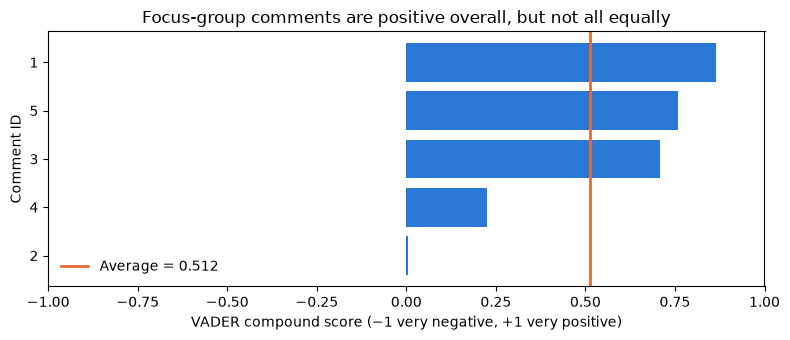

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ordered = reviews.sort_values("Sentiment_Score")
ax.barh(ordered["Review_ID"].astype(str), ordered["Sentiment_Score"], color="#2a78d6")
ax.axvline(avg_sentiment, color="#eb6834", linewidth=2, label=f"Average = {avg_sentiment:.3f}")
ax.set_xlim(-1, 1)
ax.set_title("Focus-group comments are positive overall, but not all equally")
ax.set_xlabel("VADER compound score (−1 very negative, +1 very positive)")
ax.set_ylabel("Comment ID")
ax.legend(frameon=False, loc="lower left")
plt.tight_layout()
plt.show()

> **Read before you move on**
>
> Write down your multiplier, rounded to **3 decimals** as printed above; you type it into Excel in Part 2. Read the two lowest-scoring comments: what do they complain about? A good report mentions what the multiplier **hides** (five comments is a very small sample; mixed comments score close to neutral).

---

## Part 2: Five-year financial model in Excel

Apply the multiplier to the demand plan and compare the profit of the two suppliers. Amounts are in US dollars.

**Assumptions**

| Item | Value |
|---|---|
| Selling price per unit | 200 |
| Fixed costs per year | 500,000 |
| Standard supplier: cost to build one unit | 120, so the **margin is 80** per unit |
| Ethical (Fair-Trade Green Certified) supplier: cost to build one unit | 140, so the **margin is 60** per unit |
| Base demand plan, years 1–5 (units) | 10,000; 15,000; 22,000; 30,000; 45,000 (also in `data/ecovate_base_demand.csv`) |

**Steps**

1. Open a blank Excel workbook and save it as `YourLastName_DATA300_Capstone.xlsx`.
2. In row 1, type these headers in cells **A1 to F1**: `Year`, `Base_Demand`, `Demand_Multiplier`, `Adjusted_Demand`, `Standard_Profit`, `Ethical_Profit`.
3. In **A2:A6** type the years 1 to 5. In **B2:B6** type the base demand for each year from the table above.
4. In **C2:C6** type your demand multiplier from Part 1 (the same 3-decimal number in every row).
5. In **D2** type `=ROUND(B2*C2, 0)` and fill it down to D6. This is the sentiment-adjusted demand in whole units.
6. In **E2** type `=(D2*80)-500000` and fill down to E6: profit with the standard supplier (units × margin − fixed costs).
7. In **F2** type `=(D2*60)-500000` and fill down to F6: profit with the ethical supplier.
8. Format columns E and F as currency. Save and close the workbook (Tableau cannot read a file that is open in Excel on some computers).

> **Better practice (optional, recommended)**
>
> Professional models keep assumptions in labelled cells, not inside formulas. You may put the price, costs and fixed costs in an assumptions block (for example in H1:I5) and refer to them with absolute references such as `$I$3`. Your results must be the same.

### Check your Excel model

The next cell builds the same table in Python from the bundled demand plan and your multiplier. Your Excel sheet should match it **exactly**. If it does not, check that you typed the multiplier rounded to 3 decimals and that the formulas were filled down.

In [5]:
PRICE, FIXED = 200, 500_000
MARGIN_STANDARD, MARGIN_ETHICAL = PRICE - 120, PRICE - 140

plan = pd.read_csv("data/ecovate_base_demand.csv")
plan["Demand_Multiplier"] = round(demand_multiplier, 3)
# Excel's ROUND rounds halves away from zero; this matches it for positive numbers
plan["Adjusted_Demand"] = (plan["Base_Demand"] * plan["Demand_Multiplier"] + 0.5).astype(int)
plan["Standard_Profit"] = plan["Adjusted_Demand"] * MARGIN_STANDARD - FIXED
plan["Ethical_Profit"] = plan["Adjusted_Demand"] * MARGIN_ETHICAL - FIXED
plan

,Year,Base_Demand,Demand_Multiplier,Adjusted_Demand,Standard_Profit,Ethical_Profit
0,1,10000,1.102,11020,381600,161200
1,2,15000,1.102,16530,822400,491800
2,3,22000,1.102,24244,1439520,954640
3,4,30000,1.102,33060,2144800,1483600
4,5,45000,1.102,49590,3467200,2475400


### How severe is the profit gap? (evidence you may quote)

Question 1 of the report asks how severe the profit loss from the ethical supplier is. The cell below measures it in three ways: in money each year, in per cent, and as the **extra demand** the ethical option would need to earn the same profit as the standard one. You do not have to use all of these; choose what helps your argument.

In [6]:
gap = plan[["Year"]].copy()
gap["Gap"] = plan["Standard_Profit"] - plan["Ethical_Profit"]
gap["Gap_%_of_Standard"] = (100 * gap["Gap"] / plan["Standard_Profit"]).round(1)
# Units the ethical option needs so that units x 60 - fixed = the standard profit
gap["Ethical_Units_Needed"] = ((plan["Standard_Profit"] + FIXED) / MARGIN_ETHICAL).round(0).astype(int)
gap["Extra_Demand_%"] = (100 * (gap["Ethical_Units_Needed"] / plan["Adjusted_Demand"] - 1)).round(1)
print(gap.to_string(index=False))

total_std, total_eth = plan["Standard_Profit"].sum(), plan["Ethical_Profit"].sum()
print(f"\nFive-year profit, standard: {total_std:,.0f} | ethical: {total_eth:,.0f}")
print(f"Five-year gap: {total_std - total_eth:,.0f} ({100 * (total_std - total_eth) / total_std:.1f}% of the standard profit)")
print(f"Both options are profitable in every year: {bool((plan[['Standard_Profit', 'Ethical_Profit']] > 0).all().all())}")

 Year    Gap  Gap_%_of_Standard  Ethical_Units_Needed  Extra_Demand_%
    1 220400               57.8                 14693            33.3
    2 330600               40.2                 22040            33.3
    3 484880               33.7                 32325            33.3
    4 661200               30.8                 44080            33.3
    5 991800               28.6                 66120            33.3

Five-year profit, standard: 8,255,520 | ethical: 5,566,640
Five-year gap: 2,688,880 (32.6% of the standard profit)
Both options are profitable in every year: True


### What if the focus groups were wrong? (optional sensitivity check)

Five comments are a thin basis for a five-year contract. A model is more useful when it shows how the answer changes if a key input is wrong. The cell below repeats the five-year totals for the whole range of multipliers the rule allows: from 0.800 (every comment as negative as possible) through 1.000 (ignore the focus groups) and your multiplier, to 1.200 (every comment as positive as possible). You may quote it in your report, or build the same what-if table in Excel with a **Data Table** (Day 5).

In [7]:
rows = []
for m in sorted({0.8, 0.9, 1.0, round(demand_multiplier, 3), 1.1, 1.2}):
    units = (plan["Base_Demand"] * m + 0.5).astype(int)
    rows.append({
        "Multiplier": m,
        "5-yr standard profit": (units * MARGIN_STANDARD - FIXED).sum(),
        "5-yr ethical profit": (units * MARGIN_ETHICAL - FIXED).sum(),
        "Ethical years with a loss": int(((units * MARGIN_ETHICAL - FIXED) < 0).sum()),
    })
print(pd.DataFrame(rows).to_string(index=False))

 Multiplier  5-yr standard profit  5-yr ethical profit  Ethical years with a loss
      0.800               5308000              3356000                          1
      0.900               6284000              4088000                          0
      1.000               7260000              4820000                          0
      1.100               8236000              5552000                          0
      1.102               8255520              5566640                          0
      1.200               9212000              6284000                          0


---

## Part 3: Executive chart in Tableau

Chart the two profit paths so the board sees the choice at a glance.

1. Open **Tableau Desktop**. Under **Connect**, choose **Microsoft Excel** and open `YourLastName_DATA300_Capstone.xlsx`. Open **Sheet 1**.
2. Drag **Year** to **Columns**. Right-click the pill and choose **Dimension**, so each year is its own position on the axis.
3. Drag **Measure Values** to **Rows**.
4. On the **Measure Values** card (below the Marks card), remove every measure except **SUM(Standard Profit)** and **SUM(Ethical Profit)**.
5. On the **Marks** card, choose **Line** or **Bar** (side-by-side bars), whichever shows the comparison more clearly.
6. Drag **Measure Names** to **Colour** so the two suppliers are distinguished, and use two colours that colour-blind readers can tell apart (for example blue and orange).
7. Double-click the profit axis (or right-click → **Format**) and set the numbers to **Currency**.
8. Replace the sheet title with a **message title** that states the finding, with one number (Day 2), not "Sheet 1".
9. Export the chart: **Worksheet → Export → Image…**, then insert the image in a blank **Word** document. This document becomes your report.

---

## Part 4: Managerial report

In the Word document that holds your Tableau chart, write an **executive summary** for the board: a short **introduction** (the decision, the data and the three tools), then answers to the two questions below. Write for non-technical executives: lead with your recommendation, quote numbers with units, and say what the numbers cannot tell you. Follow APA 7th edition for the cover page, headings, citations and references. As a guide, about two to three pages of text is enough, not counting the cover page, the chart and the references.

### Question 1: Strategic and ethical recommendation (CLO 5)

Your chart shows that the ethical supplier earns **less profit than the standard supplier in every year**. Assume also that the focus groups showed that EcoVate's **target customers care strongly about a company's carbon footprint**.

As lead BI analyst, recommend **one** supplier to the board, standard or ethical, and justify it. Your justification should:

- state **how large** the profit sacrifice is (in money and in per cent, over the five years and in the early years), and whether both options stay profitable;
- weigh it against the **ethical and societal context**: emissions, the supplier's record, the customers' values, and the risk to the brand, to future sales and from regulation;
- consider **long-term brand value**, not only the five-year profit in the model;
- name the main **assumptions and limits** (for example the small focus group, fixed prices and costs) and what you would monitor after the decision.

### Question 2: The value of an integrated BI workflow

In this project you moved the evidence across three tools: **text mining in Python → financial model in Excel → visual story in Tableau**. Explain why linking these three steps gives the board a **more robust and realistic** plan than a single static spreadsheet would. Refer to what each step added in this case, and to at least one risk of the workflow (for example an error carried from one tool to the next) and how you controlled it.

---

## Part 5: Export and submit

You submit **three deliverables**.

| Step | What to do | File name |
|---|---|---|
| 1 | In JupyterLab, run **Kernel → Restart Kernel and Run All Cells** and check that the table, the multiplier and the chart are visible | |
| 2 | Export the notebook to PDF: **File → Save and Export Notebook As → HTML**, open the HTML in your browser, then **Print → Save as PDF** (or **File → Print** in JupyterLab) | `LastName_JupyterLabLab.pdf` |
| 3 | Save your Word report (cover page, introduction, chart, answers to both questions, references) as PDF. You may attach the notebook PDF at the end of the report as an appendix, or submit it as a separate file | `YourLastName_Capstone_Report.pdf` |
| 4 | Keep the Excel workbook with the formulas (not only values) | `YourLastName_DATA300_Capstone.xlsx` |
| 5 | Log in to **GAP (Moodle)**, open the **DATA 300: Assignment 4** drop-box, upload the files and click **Submit** before the deadline | |

To join the notebook PDF to the end of your report without internet access, see [Combining PDFs without internet](setup.md#combining-pdfs-without-internet).

---

## How it is marked

The capstone is marked out of 100 with the course's capstone rubric, then scaled to its 25% weight.

| Criterion | Points | What earns them here |
|---|---|---|
| **CLO 4**: develop predictive models (forecasting, regression, spreadsheet simulation) to project future outcomes | 40 | A correct multiplier from the executed notebook; a working Excel model with formulas that match the check table; a correct reading of the five-year profit paths; better answers test how sensitive the result is to the multiplier |
| **CLO 5**: evaluate BI tools within a case study to produce managerial reports that consider ethical and societal contexts | 40 | A clear recommendation that weighs the size of the profit gap against ethics, customers and brand risk; a reasoned evaluation of the Python → Excel → Tableau workflow; limits and next steps |
| **Scholarly and professional formatting** | 10 | APA 7th edition format (cover page, headings, citations and references); a readable chart with a message title and currency axis; all three files with the right names |
| **Academic writing and mechanics** | 10 | Clear, organised, professional language for a non-technical board; correct grammar and terms |

Each criterion is judged on a scale from *exemplary* (full points) through *excellent*, *proficient*, *developing* and *unsatisfactory*; a missing or unacceptable submission scores 0.

---

## Studio plan for this afternoon (13:45–17:20)

Use the lab to get through the technical parts with help in the room, so that the post-class week is for thinking and writing. Show your work to the facilitator, or to a classmate where it says *peer*, at each checkpoint.

| Time | Milestone | Checkpoint (show by the time given) |
|---|---|---|
| 13:45–14:00 | Launch: the scenario, the three deliverables, how it is marked | Your copy is saved as `YourLastName_DATA300_Capstone.ipynb` next to the `data` folder |
| 14:00–14:30 | **Milestone 1:** Part 1 runs from top to bottom | **Checkpoint 1 (14:30):** the sentiment table, the chart and your multiplier are on screen; you can explain the multiplier rule in one sentence |
| 14:30–15:25 | **Milestone 2:** the Excel model is built with formulas | **Checkpoint 2 (15:25):** your Excel sheet matches the check table in Part 2, row by row |
| 15:25–15:40 | Break | |
| 15:40–16:30 | **Milestone 3:** the Tableau chart is built, formatted and exported into Word | **Checkpoint 3 (16:30), peer:** a classmate reads only your chart for 30 seconds and says which supplier earns more and roughly by how much. If they cannot, improve the title, colours or axis |
| 16:30–17:10 | **Milestone 4:** the report plan: introduction in three sentences; your one-sentence recommendation for Question 1 with two numbers; three bullet points for Question 2 | **Checkpoint 4 (17:10):** facilitator feedback on your recommendation sentence: is it clear, supported by numbers, and does it weigh ethics against money? |
| 17:10–17:20 | Wrap-up: save all files; write your plan for finishing the report by Sunday 29 November | **By 17:20:** checkpoints 1–4 done, or a written note of what is left and when you will do it |

If you finish early, use the time for the optional sensitivity check, or for **Assignments 2 and 3** (due Sunday 22 November); the facilitator also takes questions on those during the studio.

---

## Final checklist

- [ ] My notebook is saved as `YourLastName_DATA300_Capstone.ipynb`, runs from top to bottom without errors, and is exported as `LastName_JupyterLabLab.pdf`.
- [ ] My Excel workbook `YourLastName_DATA300_Capstone.xlsx` has the six headers, my multiplier to 3 decimals, and **formulas** that match the check table.
- [ ] My Tableau chart shows both profit paths by year, with a message title, a currency axis and distinguishable colours, and is in my Word report.
- [ ] My report has an introduction and answers both questions; Question 1 recommends **one** supplier and quantifies the profit gap; Question 2 explains what each tool added.
- [ ] I name the main limits (for example only five comments) and what to monitor.
- [ ] APA 7th edition: cover page, headings, citations and references.
- [ ] `YourLastName_Capstone_Report.pdf` (with or without the notebook PDF attached), the notebook PDF if separate, and the Excel file are uploaded to GAP by **Sunday 29 November, 23:59 China Standard Time**.